# Module 3 · Reading what my detector produces
This notebook uses **your** `src/evaluate.py` with the model you trained on the page *2 · Training*. Change `RUN` to the name of your run. It writes the figures your Assignment 3.2 needs.

In [1]:
import json, sys
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
ROOT = Path("..") if Path("../src").exists() else Path(".")
sys.path.insert(0, str(ROOT))
from src import data as dt, evaluate as ev

RUN = "all30"                       # the name of your training run
project = dt.load_project(ROOT / "project.yaml")
classes = project["classes"]
data_root = ROOT / "data" / f"{project['name']}_yolo"
weights = ROOT / "runs" / RUN / "weights" / "best.pt"
yaml_path = data_root / "data.yaml"
(ROOT / "results").mkdir(exist_ok=True)
print(weights, weights.exists())

..\runs\all30\weights\best.pt True


## 1. The score on photos the model never saw
mAP goes through all the confidence values, so it has no threshold of its own.

In [2]:
metrics = ev.yolo_metrics(weights, yaml_path)
print(json.dumps(metrics, indent=1))

Ultralytics 8.4.188  Python-3.12.7 torch-2.2.2+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1066.4±583.5 MB/s, size: 787.5 KB)
val: Scanning C:\Users\yayab\Documents\AI Course Homework\MAI 630 Computer Vision\my-detector\data\bottles_yolo\labels\test.cache... 648 images, 0 backgrounds, 3 corrupt: 100% ━━━━━━━━━━━━ 648/648  0.0s
val: C:\Users\yayab\Documents\AI Course Homework\MAI 630 Computer Vision\my-detector\data\bottles_yolo\images\test\Plastic-water-bottles-1-Pixabay_jpg.rf.d950dfcc89278eec476252d2e918995b.jpg: ignoring corrupt image/label: labels mix segment and detection rows
val: C:\Users\yayab\Documents\AI Course Homework\MAI 630 Computer Vision\my-detector\data\bottles_yolo\images\test\prod-20210107-2040154710673891208371735-jpg-500x500_jpg.rf.df7dae216251d2eb0f99a7e551f6ddec.jpg: ignoring corrupt image/label: labels mix segment and detectio

## 2. The same photos at four thresholds

skipped 3 image(s) whose labels mix boxes and polygons: ['Plastic-water-bottles-1-Pixabay_jpg.rf.d950dfcc89278eec476252d2e918995b.jpg', 'prod-20210107-2040154710673891208371735-jpg-500x500_jpg.rf.df7dae216251d2eb0f99a7e551f6ddec.jpg', 'water-bottles_png.rf.19b928676992b11c25ab242477d4f127.jpg']
645 images evaluated
conf 0.10 · TP  422 · FP  520 · FN  354 · precision 0.45 · recall 0.54
conf 0.25 · TP  397 · FP  286 · FN  379 · precision 0.58 · recall 0.51
conf 0.50 · TP  292 · FP  123 · FN  484 · precision 0.70 · recall 0.38
conf 0.75 · TP  122 · FP   11 · FN  654 · precision 0.92 · recall 0.16
from 0.25 to 0.75: {'removed_correct': 275, 'removed_wrong': 275}


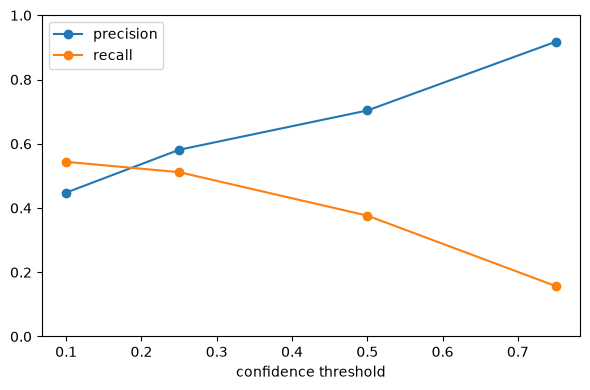

In [3]:
images = ev.predict_images(weights, data_root / "images" / "test", data_root / "labels" / "test", classes)
table = ev.threshold_table(images)
for r in table:
    print(f"conf {r['conf']:.2f} · TP {r['tp']:4d} · FP {r['fp']:4d} · FN {r['fn']:4d} · precision {r['precision']:.2f} · recall {r['recall']:.2f}")
print("from 0.25 to 0.75:", ev.what_changed(images, 0.25, 0.75))
json.dump(table, open(ROOT / "results" / "thresholds.json", "w"), indent=1)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([r["conf"] for r in table], [r["precision"] for r in table], "-o", label="precision")
ax.plot([r["conf"] for r in table], [r["recall"] for r in table], "-o", label="recall")
ax.set_xlabel("confidence threshold"); ax.set_ylim(0, 1); ax.legend(); fig.tight_layout()
fig.savefig(ROOT / "results" / "thresholds.png", dpi=150); plt.show()

## 3. Look at the images
Green: correct. Red: false alarm. Yellow: an object the detector missed.

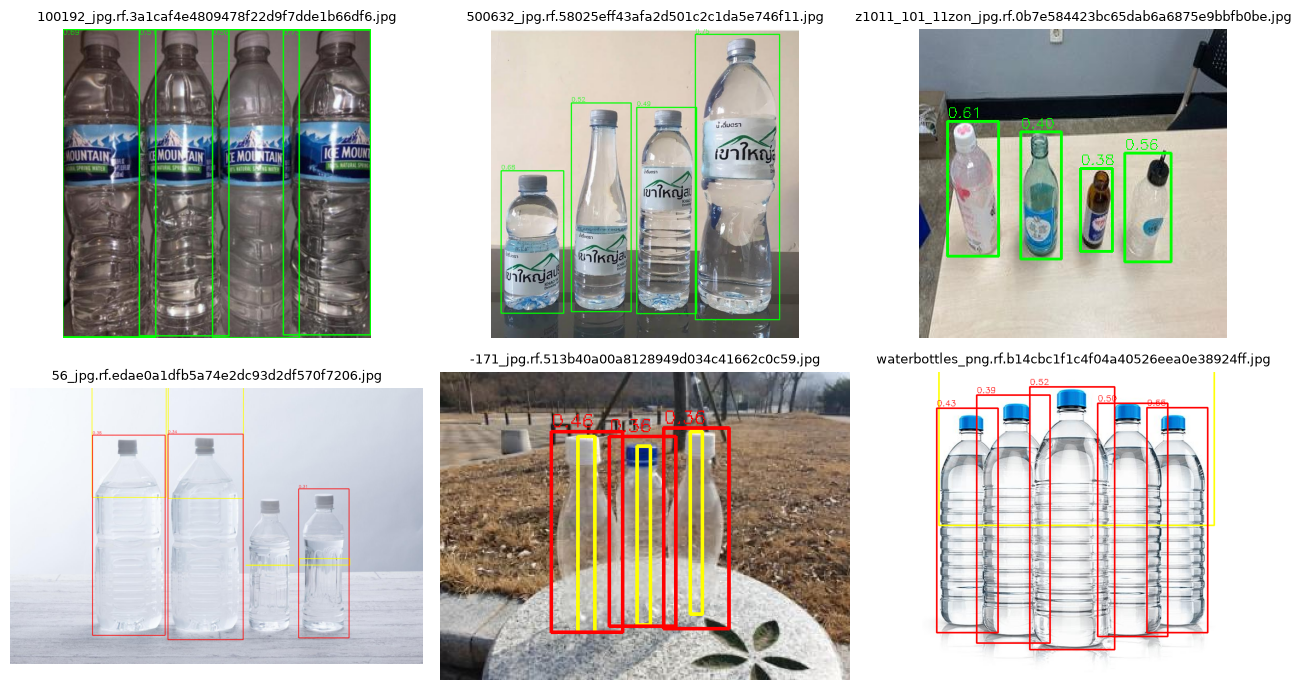

{'correct': ['100192_jpg.rf.3a1caf4e4809478f22d9f7dde1b66df6.jpg', '500632_jpg.rf.58025eff43afa2d501c2c1da5e746f11.jpg', 'z1011_101_11zon_jpg.rf.0b7e584423bc65dab6a6875e9bbfb0be.jpg'], 'wrong': ['56_jpg.rf.edae0a1dfb5a74e2dc93d2df570f7206.jpg', '-171_jpg.rf.513b40a00a8128949d034c41662c0c59.jpg', 'waterbottles_png.rf.b14cbc1f1c4f04a40526eea0e38924ff.jpg']}


In [4]:
def panel(name):
    rgb = cv2.cvtColor(cv2.imread(str(data_root / "images" / "test" / name)), cv2.COLOR_BGR2RGB)
    d = images[name]
    return ev.draw_result(rgb, ev.match([p for p in d["preds"] if p["score"] >= 0.25], d["truths"]))
picked = ev.pick_examples(images, conf=0.25, n=3)
names = picked["correct"] + picked["wrong"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, n in zip(axes.flat, names):
    ax.imshow(panel(n)); ax.set_title(n, fontsize=9)
for ax in axes.flat: ax.axis("off")
fig.tight_layout(); fig.savefig(ROOT / "results" / "examples.png", dpi=150); plt.show()
print(picked)

## 4. Now it is your turn
Ask the subagent `image-auditor` to look at `results/examples.png`, and `metrics-reviewer` to read your draft. They point things out. **The interpretation is yours.**